# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [2]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv(r'C:\Users\Dell\co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [3]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: ['United States' 'China' 'India' 'Germany' 'United Kingdom' 'France'
 'Brazil' 'Japan' 'Canada' 'Australia' 'South Korea' 'Russia'
 'South Africa' 'Mexico' 'Indonesia']

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


## Task 1 - A line chart showing CO2 per Capita for all countries in the dataset

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

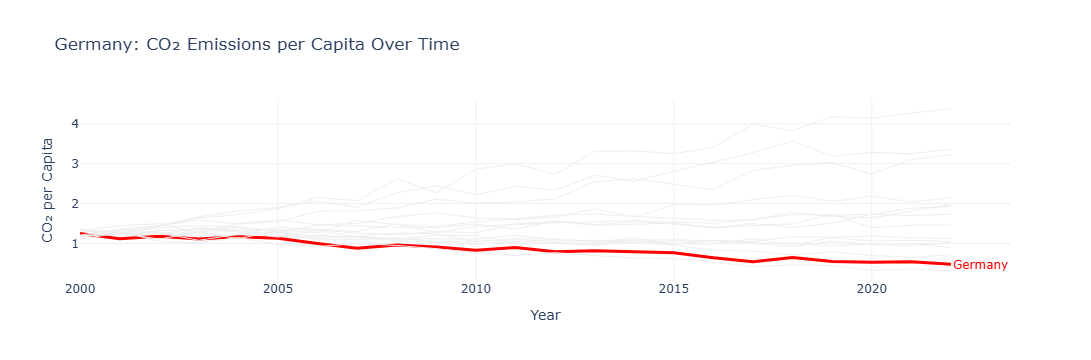

In [8]:
import plotly.graph_objects as go

fig = go.Figure()

for country, data in df.groupby('Country'):
    data = data.sort_values('Year')

    fig.add_trace(go.Scatter(
        x=data['Year'],
        y=data['CO2_per_capita'],
        mode='lines',
        line=dict(
            color='red' if country == 'Germany' else '#EEEEEE',
            width=3 if country == 'Germany' else 1
        ),
        showlegend=False
    ))

# Label Germany at the end of its line
germany = df[df['Country'] == 'Germany'].sort_values('Year')

if not germany.empty:
    fig.add_annotation(
        x=germany['Year'].iloc[-1],
        y=germany['CO2_per_capita'].iloc[-1],
        text='Germany',
        showarrow=False,
        xshift=30,
        font=dict(color='red')
    )

fig.update_layout(
    title='Germany: CO₂ Emissions per Capita Over Time',
    xaxis_title='Year',
    yaxis_title='CO₂ per Capita',
    template='plotly_white',
    showlegend=False
)

fig.show()

---
## Task 2 — A line chart showing CO2 emissions over time for all Asian countries in the dataset, with one country highlighted.

**same requirements as Task1**

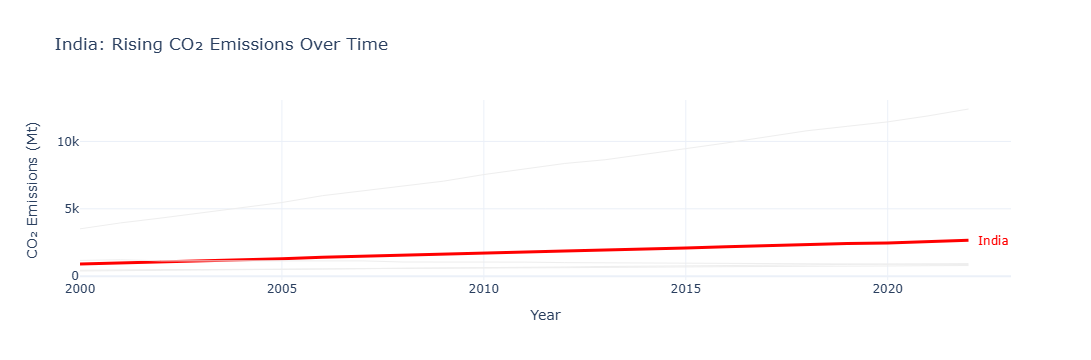

In [9]:
import plotly.graph_objects as go

asia = df[df['Region'] == 'Asia']
fig = go.Figure()

for country, data in asia.groupby('Country'):
    data = data.sort_values('Year')
    fig.add_scatter(
        x=data['Year'],
        y=data['CO2_Mt'],
        mode='lines',
        line=dict(color='red' if country == 'India' else '#EEEEEE',
                  width=3 if country == 'India' else 1),
        showlegend=False
    )

india = asia[asia['Country'] == 'India'].sort_values('Year')

fig.add_annotation(
    x=india['Year'].iloc[-1],
    y=india['CO2_Mt'].iloc[-1],
    text='India',
    showarrow=False,
    xshift=25,
    font=dict(color='red')
)

fig.update_layout(
    title='India: Rising CO₂ Emissions Over Time',
    xaxis_title='Year',
    yaxis_title='CO₂ Emissions (Mt)',
    template='plotly_white',
    showlegend=False
)

fig.show()